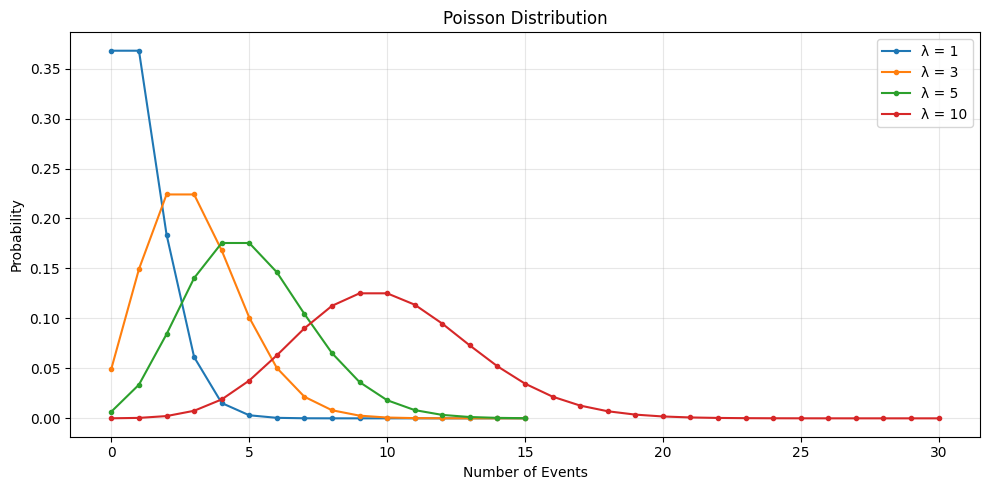

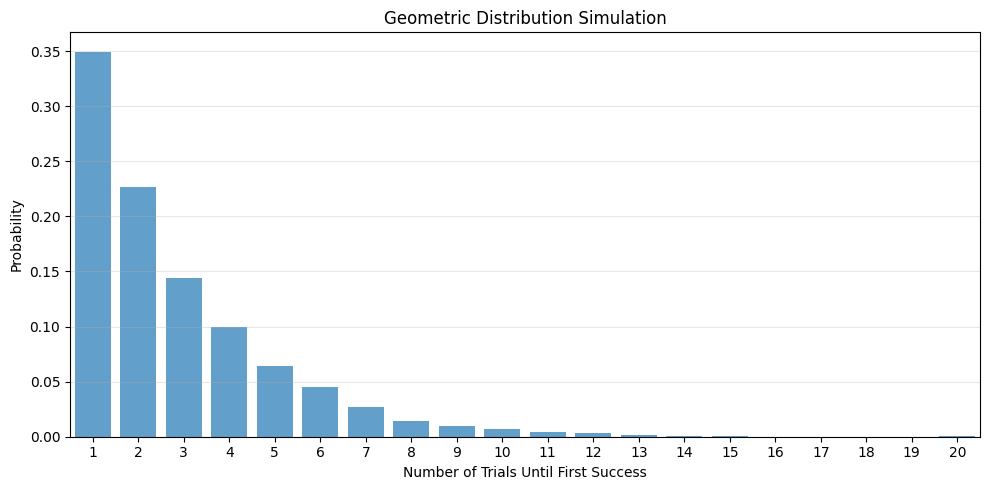


Mean Comparison:
Distribution  Parameter  Theoretical Mean  Simulation Mean
     Poisson       1.00            1.0000           0.9700
     Poisson       3.00            3.0000           3.0136
     Poisson       5.00            5.0000           4.9876
     Poisson      10.00           10.0000          10.0718
   Geometric       0.35            2.8571           2.8430


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

np.random.seed(42)

results = []

# ---------------------------------
# 1. POISSON — LINE GRAPH ONLY
# ---------------------------------
plt.figure(figsize=(10, 5))

for lam in [1, 3, 5, 10]:
    d = stats.poisson(lam)
    sim = np.random.poisson(lam, 5000)

    results.append({
        "Distribution": "Poisson",
        "Parameter": lam,
        "Theoretical Mean": d.mean(),
        "Simulation Mean": np.mean(sim)
    })

    x = np.arange(0, max(15, int(lam * 3)) + 1)

    # Simple line graph
    plt.plot(
        x, d.pmf(x),
        marker="o",
        markersize=3,
        label=f"λ = {lam}"
    )

plt.title("Poisson Distribution")
plt.xlabel("Number of Events")
plt.ylabel("Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------------
# 2. GEOMETRIC — BAR GRAPH ONLY
# ---------------------------------
p_geo = 0.35

geo = stats.geom(p_geo)
sim_geo = np.random.geometric(p_geo, 5000)

results.append({
    "Distribution": "Geometric",
    "Parameter": p_geo,
    "Theoretical Mean": geo.mean(),
    "Simulation Mean": np.mean(sim_geo)
})

# Bar graph of simulated probabilities
values, counts = np.unique(sim_geo, return_counts=True)
probabilities = counts / len(sim_geo)

plt.figure(figsize=(10, 5))

plt.bar(values, probabilities, alpha=0.7)

plt.title("Geometric Distribution Simulation")
plt.xlabel("Number of Trials Until First Success")
plt.ylabel("Probability")
plt.xticks(range(1, min(max(values), 20) + 1))
plt.xlim(0.5, 20.5)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------------
# 3. MEAN COMPARISON TABLE
# ---------------------------------
df = pd.DataFrame(results)

print("\nMean Comparison:")
print(df.round(4).to_string(index=False))